<img style="width:100%" src="https://thumbs.dreamstime.com/t/banner-shoulder-ray-blue-tone-part-rib-130883110.jpg"><br><br>
# Clasificador de radiografías
<br>

## Detección de neumonía

In [ ]:
#!pip install imblearn
#!pip install opencv-python # libreria muy optimizada


In [ ]:
from __future__ import absolute_import, division, print_function, unicode_literals

import pandas as pd
import tensorflow as tf
import keras

from keras import datasets, layers, models

import matplotlib.pyplot as plt
import numpy as np
import os
from tqdm import tqdm #barra de progreso`
import cv2
from glob import glob

#para redimensionar
import sklearn
import skimage
from skimage.transform import resize #redimensionar imagen

import random
#Usaremos datetime para nombrar archivos
import datetime

from imblearn.over_sampling import RandomOverSampler #remuestreo.
from imblearn.under_sampling import RandomUnderSampler
from skimage.color import rgb2gray

import seaborn as sns
sns.set()
%config InlineBackend.figure_format = 'retina'
plt.style.use("seaborn-white")




In [ ]:
train_dir = "chest_xray/train/"
test_dir =  "chest_xray/test/"

LOAD_FROM_IMAGES = False

def get_data(folder):
    X = []
    y = []
    for folderName in os.listdir(folder): #voy leyendo directorios
        if not folderName.startswith('.'):
            if folderName in ['NORMAL']:
                label = 0
            elif folderName in ['PNEUMONIA']:
                label = 1
            else:
                label = 2
            for image_filename in tqdm(os.listdir(folder + folderName)):
                img_file = cv2.imread(folder + folderName + '/' + image_filename)
                if img_file is not None:
                    img_file = skimage.transform.resize(img_file, (150, 150, 3),mode='constant',anti_aliasing=True)
                    img_file = rgb2gray(img_file)
                    #img_file = scipy.misc.imresize(arr=img_file, size=(150, 150, 3))
                    img_arr = np.asarray(img_file)
                    X.append(img_arr)
                    y.append(label)
    X = np.asarray(X)
    y = np.asarray(y)
    return X,y


if LOAD_FROM_IMAGES:
    #cargamos las imágenes a los arrays
    X_train, y_train = get_data(train_dir)
    X_test, y_test= get_data(test_dir)

    #grabamos los arrays en archivos
    np.save('xtrain.npy', X_train)
    np.save('ytrain.npy', y_train)
    np.save('xtest.npy', X_test)
    np.save('ytest.npy', y_test)
else:
    #cargamos los arrays anteriormente grabados
    X_train = np.load('xtrain.npy')
    y_train = np.load('ytrain.npy')
    X_test = np.load('xtest.npy')
    y_test = np.load('ytest.npy')



In [ ]:
X_train[3]

array([[0.04366013, 0.06058824, 0.06653595, ..., 0.00784314, 0.00392157,
        0.        ],
       [0.05163399, 0.07058824, 0.07777778, ..., 0.        , 0.        ,
        0.        ],
       [0.05882353, 0.0745098 , 0.08235294, ..., 0.01165577, 0.0127451 ,
        0.00729847],
       ...,
       [0.06405229, 0.11993464, 0.27189542, ..., 0.01176471, 0.01568627,
        0.03137255],
       [0.05875817, 0.12745098, 0.27254902, ..., 0.01176471, 0.01176471,
        0.02607843],
       [0.03647059, 0.11143791, 0.24888889, ..., 0.00784314, 0.00784314,
        0.00784314]])

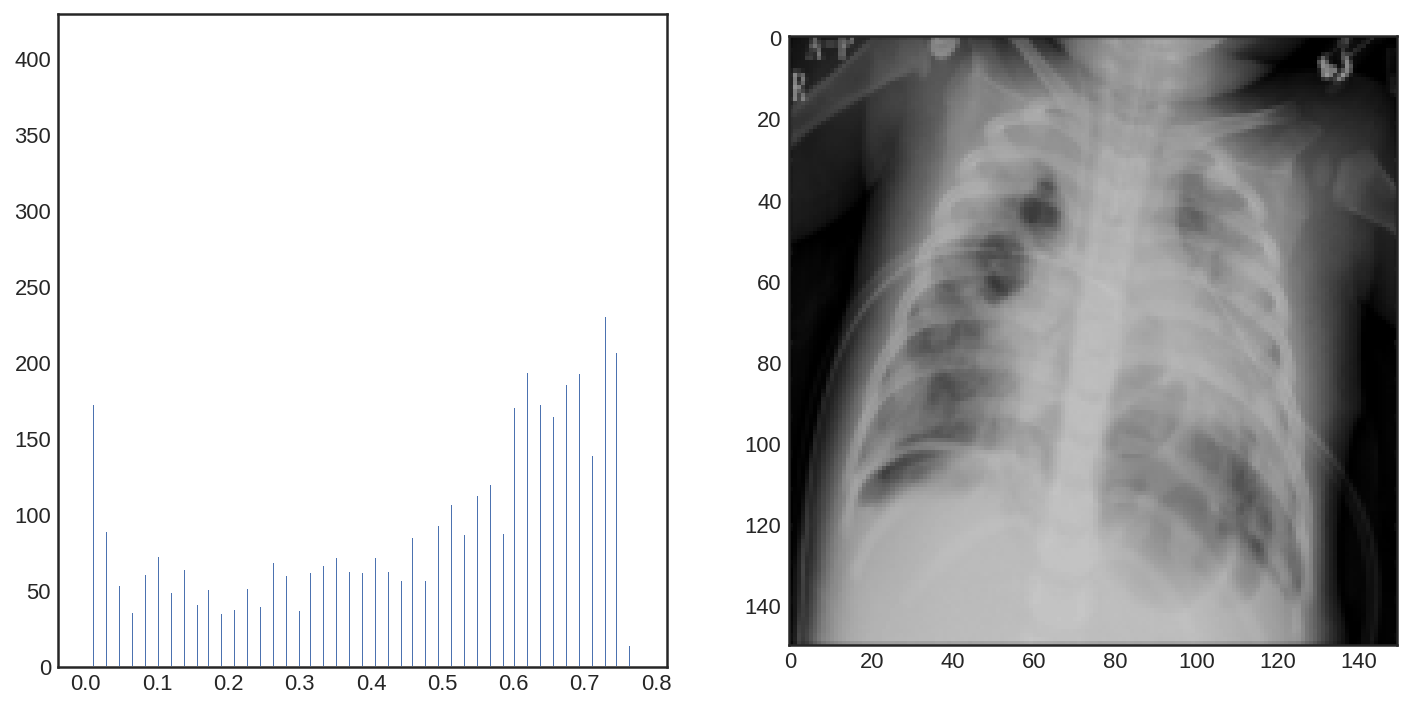

In [ ]:

def plotHistogram(a):
    plt.figure(figsize=(12,6))
    plt.subplot(1, 2, 1)
    plt.hist(a.ravel(), bins=255)
    plt.subplot(1, 2, 2)
    plt.imshow(a, cmap='gray', vmin=0, vmax=1)
    plt.show()

plotHistogram(X_train[3])
#vemos las tonalidades. histograma de la imagen.

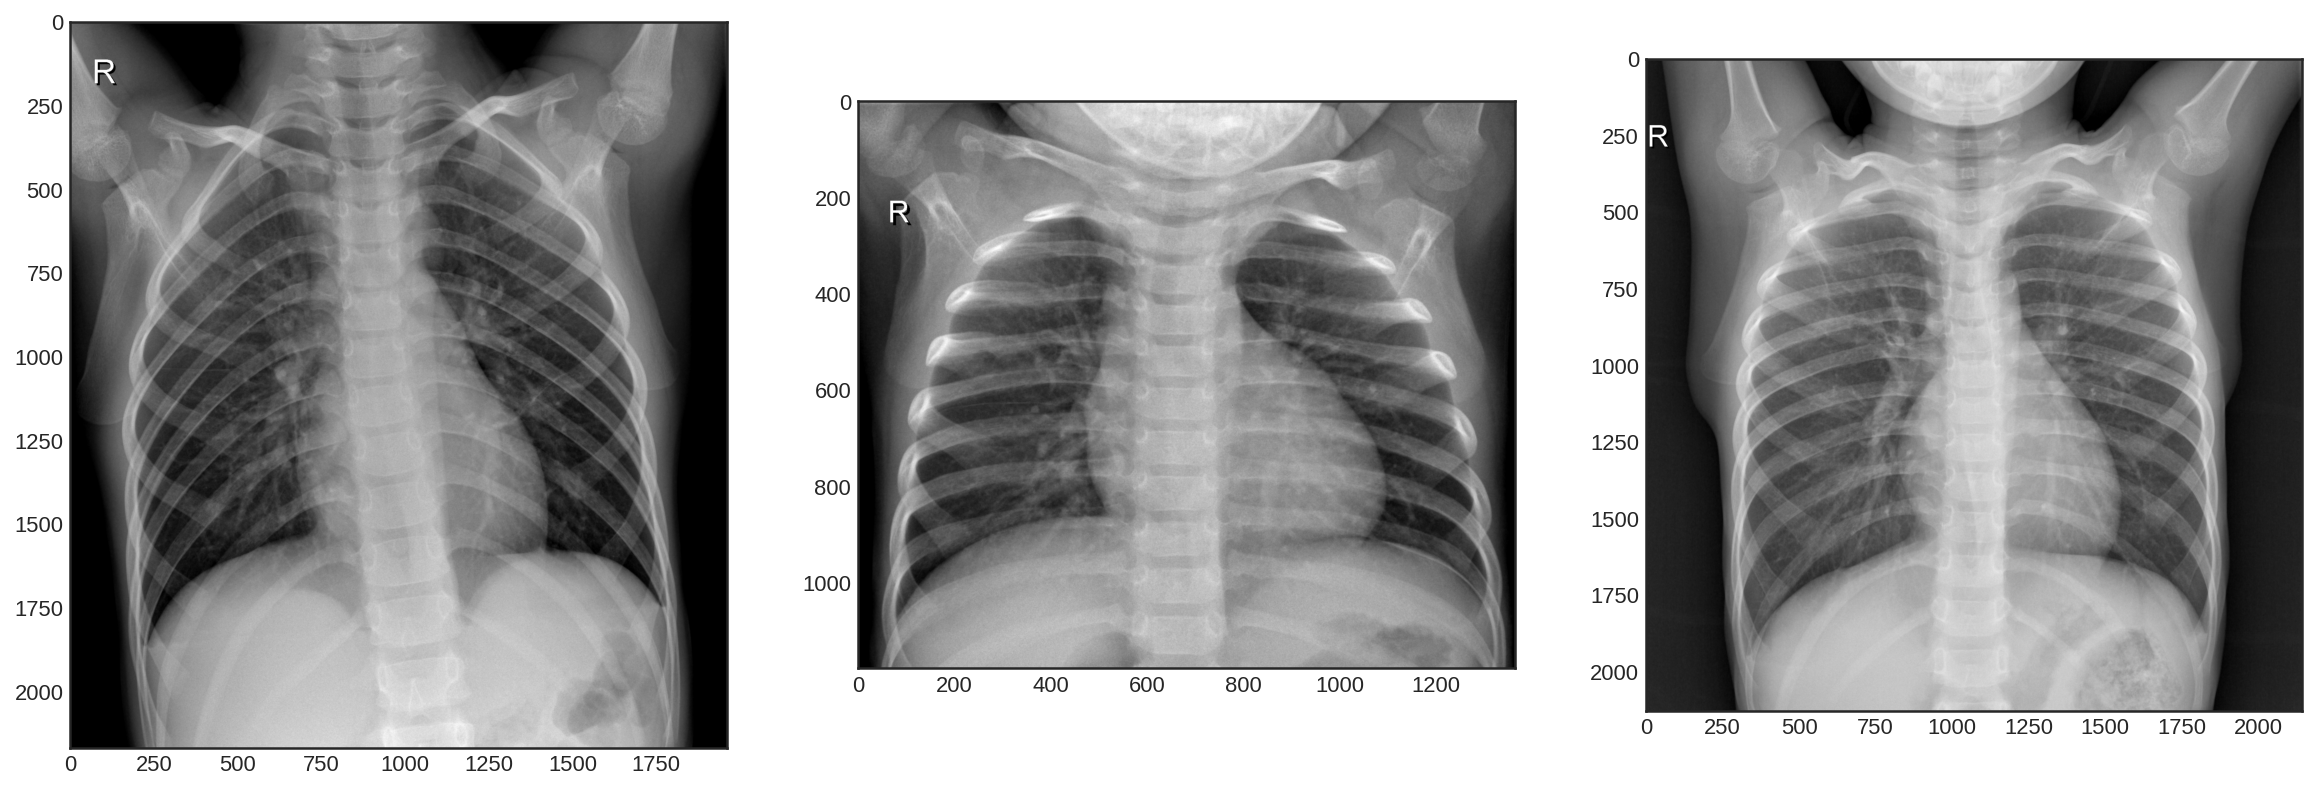

In [ ]:
multipleImages = glob('chest_xray/train/NORMAL/**')
def plotThreeImages(images):
    r = random.sample(images, 3)
    plt.figure(figsize=(20,20))
    plt.subplot(131)
    plt.imshow(cv2.imread(r[0]))
    plt.subplot(132)
    plt.imshow(cv2.imread(r[1]))
    plt.subplot(133)
    plt.imshow(cv2.imread(r[2]));
plotThreeImages(multipleImages)

No Neumonía


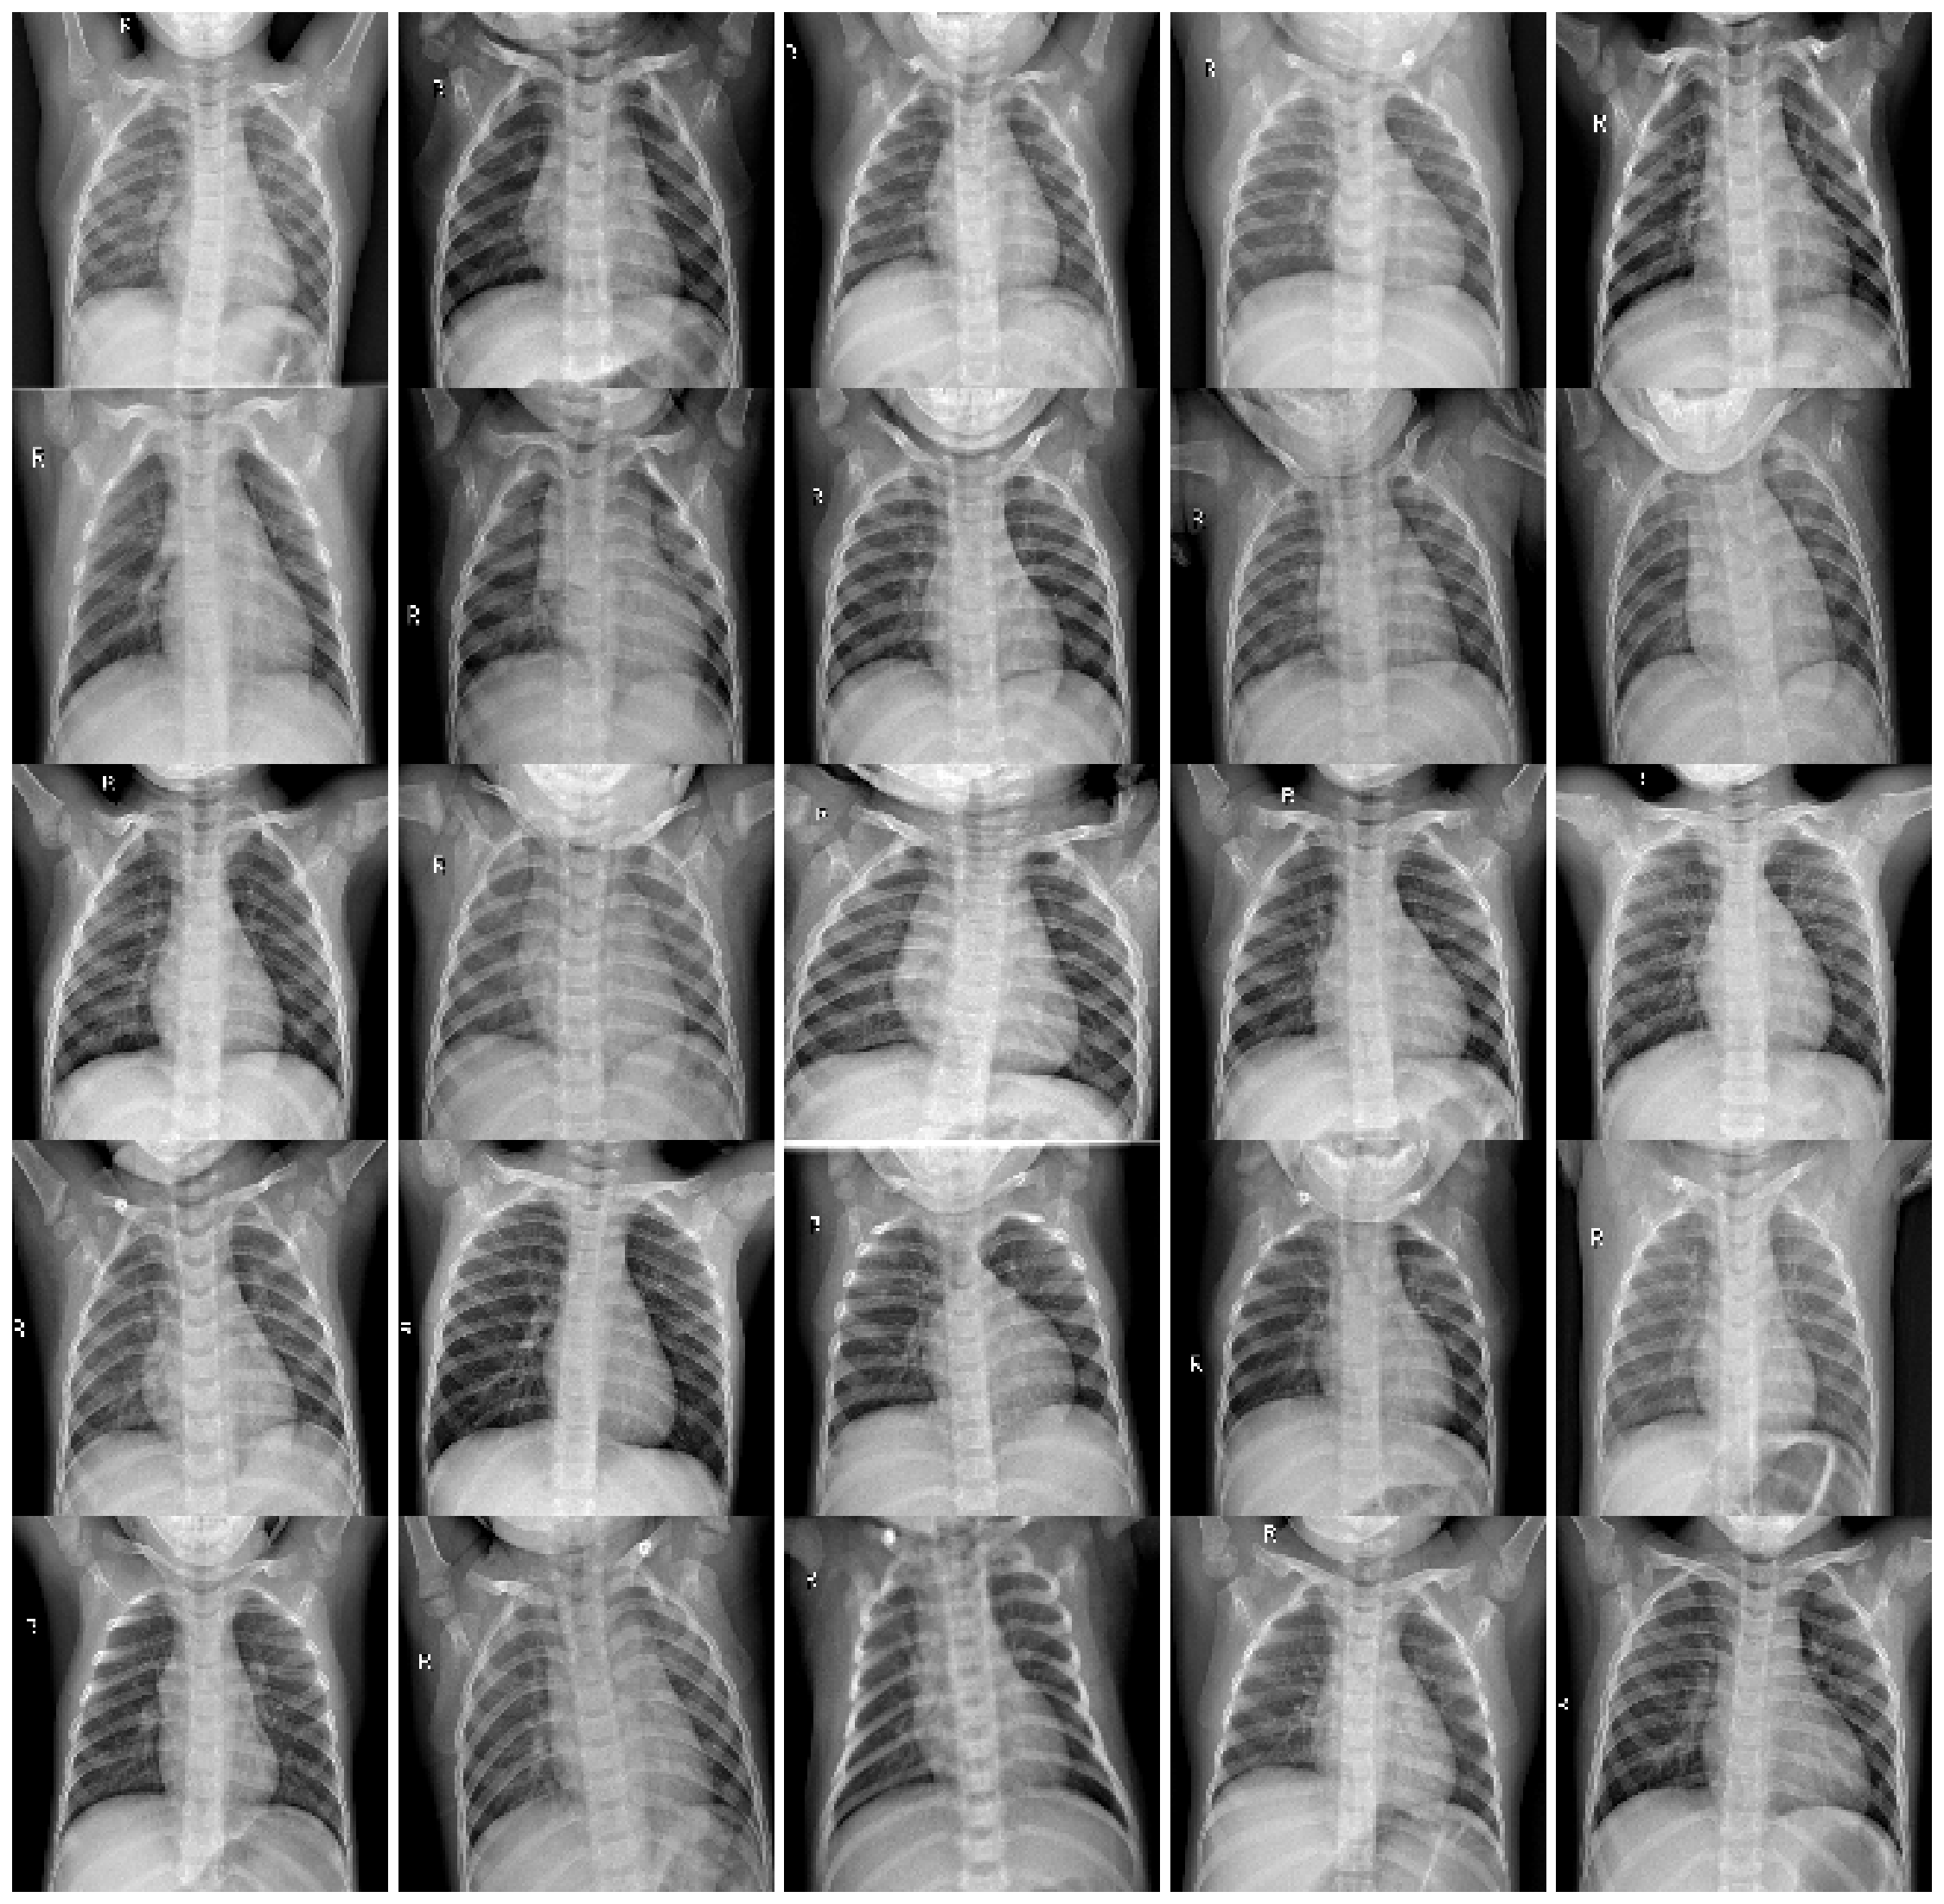

In [ ]:
print("No Neumonía")
multipleImages = glob('chest_xray/train/NORMAL/**')
i_ = 0
plt.rcParams['figure.figsize'] = (20.0, 20.0)
plt.subplots_adjust(wspace=0, hspace=0)
for l in multipleImages[:25]:
    im = cv2.imread(l)
    im = cv2.resize(im, (128, 128))
    plt.subplot(5, 5, i_+1)
    plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); plt.axis('off')
    i_ += 1

Si neumonía


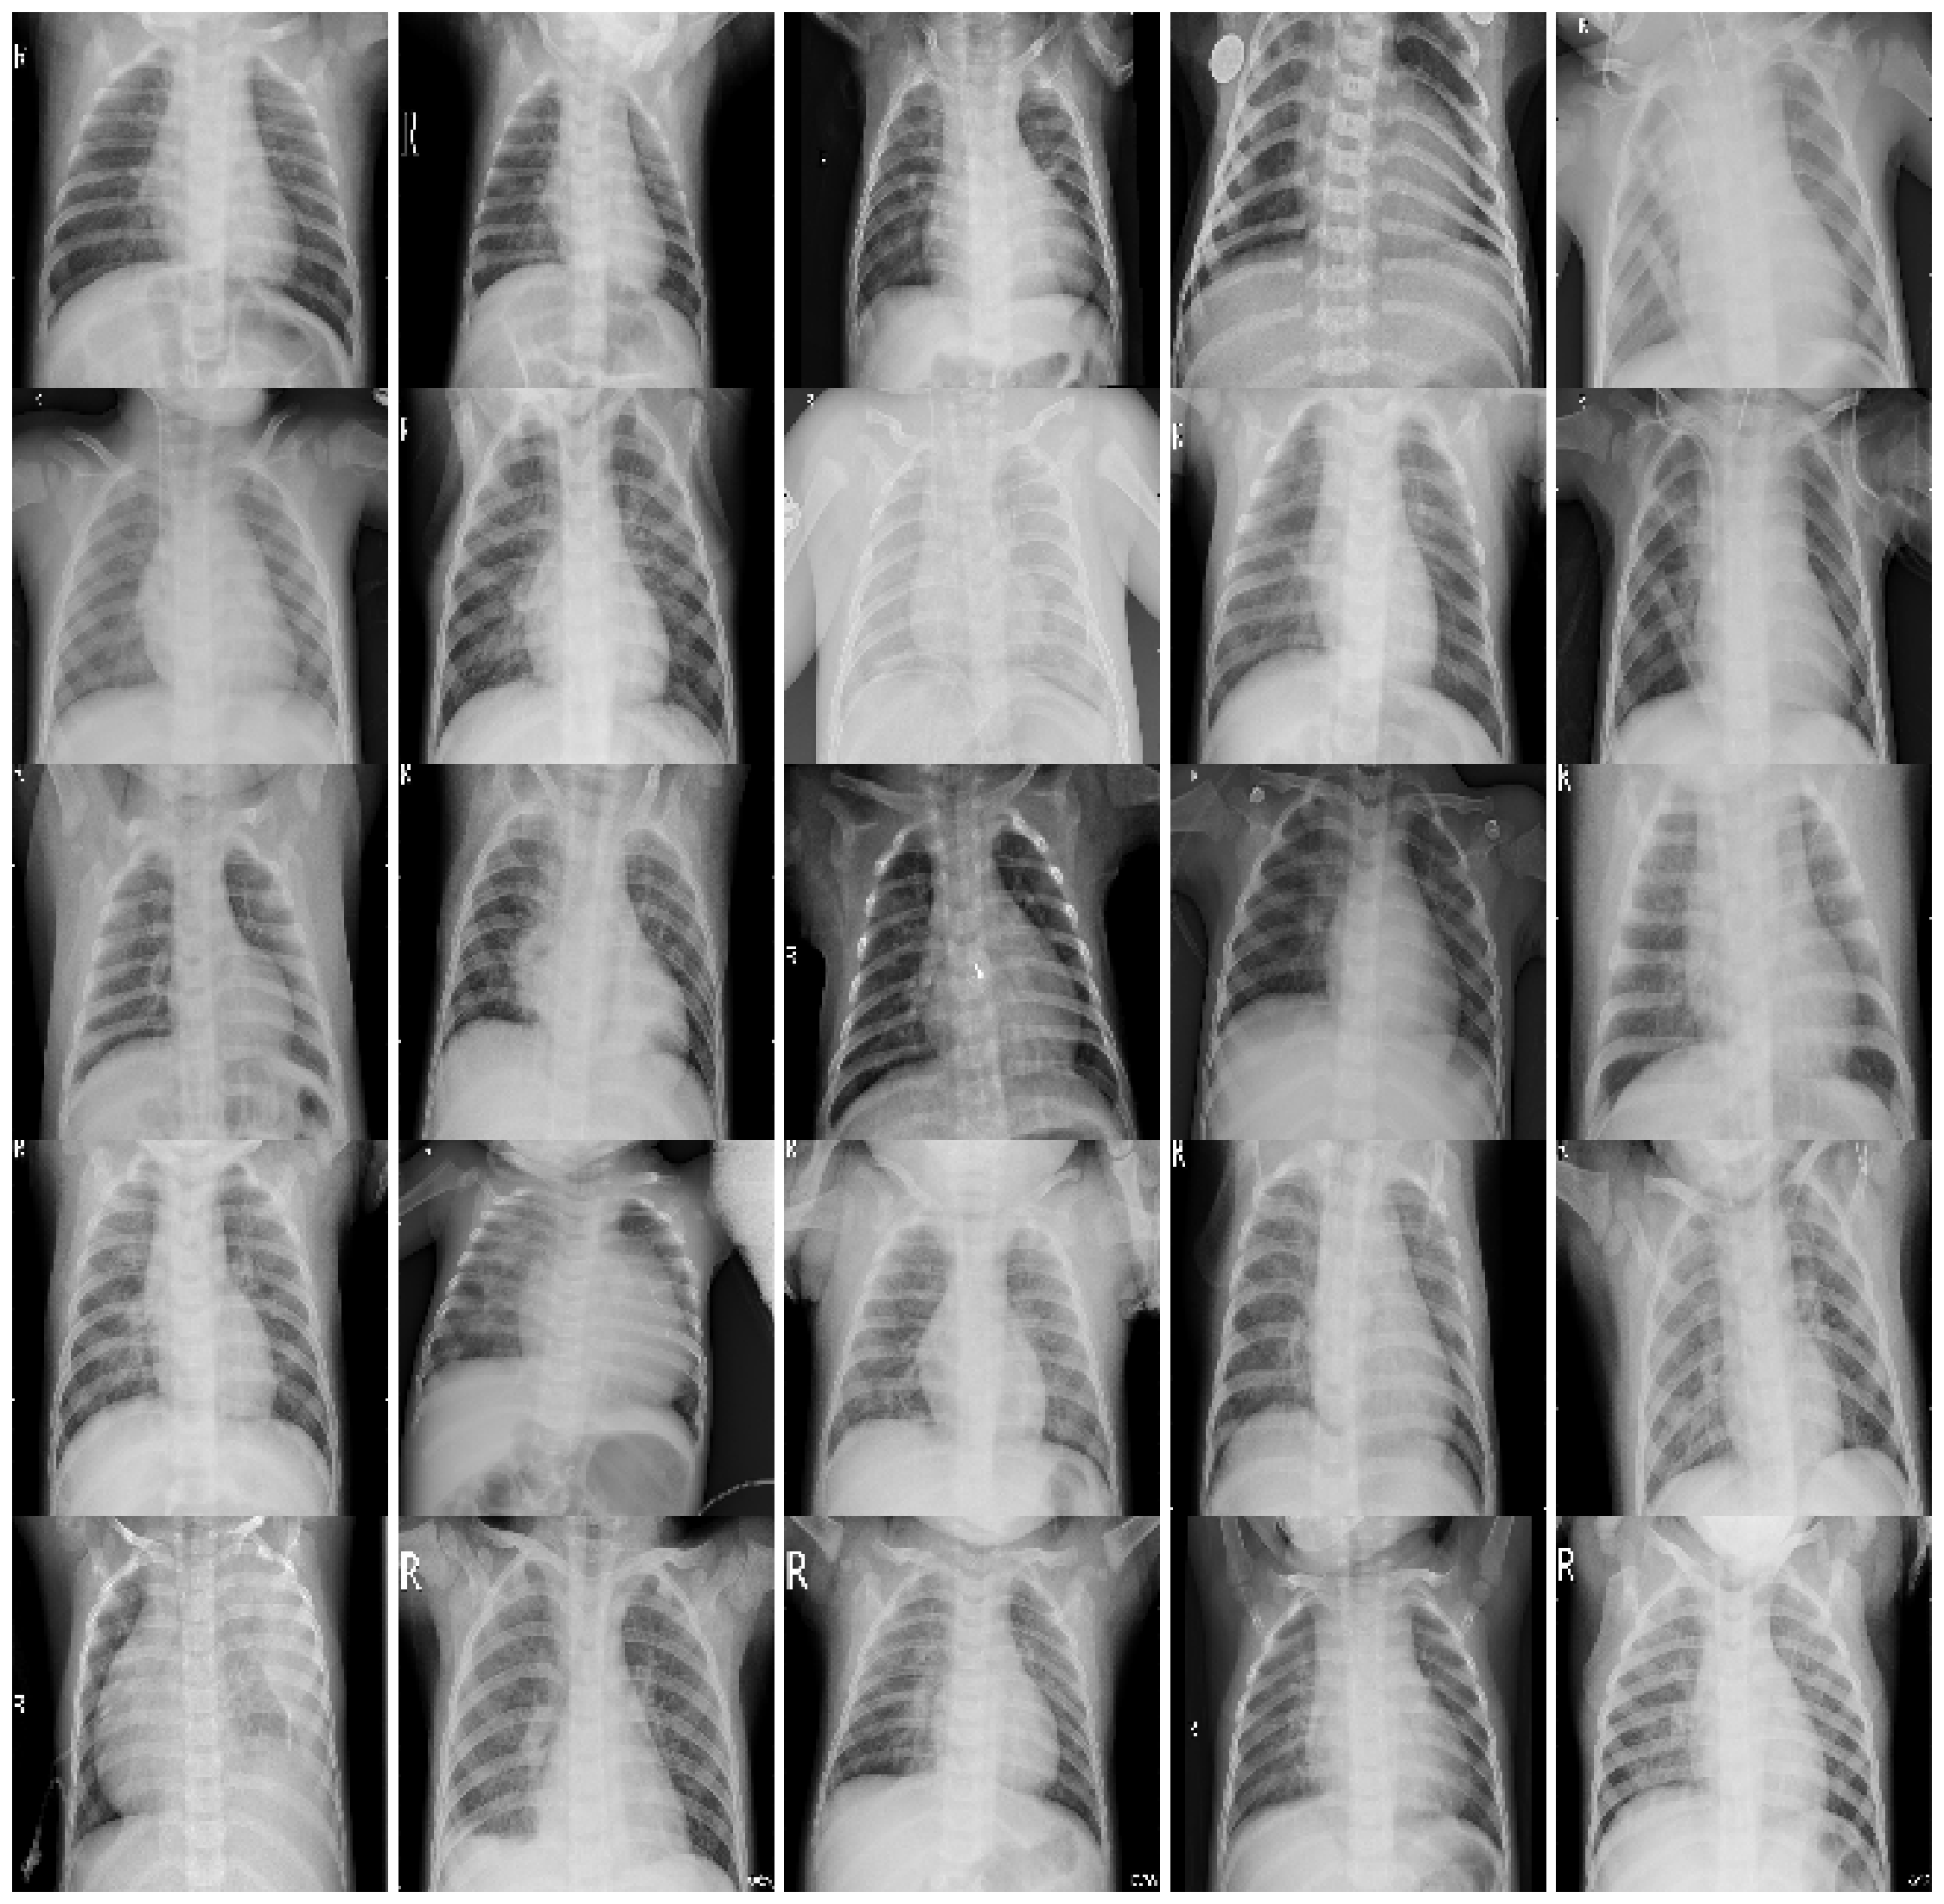

In [ ]:
print("Si neumonía")
multipleImages = glob('chest_xray/train/PNEUMONIA/**')
i_ = 0
plt.rcParams['figure.figsize'] = (20.0, 20.0)
plt.subplots_adjust(wspace=0, hspace=0)
for l in multipleImages[:25]:
    im = cv2.imread(l)
    im = cv2.resize(im, (128, 128))
    plt.subplot(5, 5, i_+1)
    plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); plt.axis('off')
    i_ += 1

{0: 'No Neumonía', 1: 'Si Neumonía'}


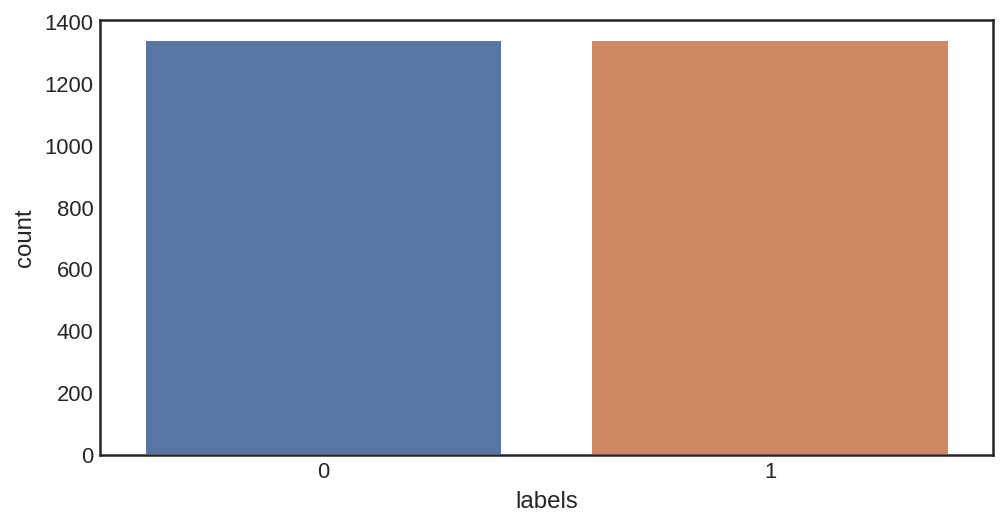

In [ ]:
import seaborn as sns

plt.figure(figsize=(8,4))
map_characters = {0: 'No Neumonía', 1: 'Si Neumonía'}
dict_characters=map_characters

df = pd.DataFrame()
df["labels"]=y_train
lab = df['labels']
dist = lab.value_counts()
sns.countplot(lab)
print(dict_characters)

In [ ]:
"""
X_trainReshaped.shape
y_train
"""


'\nX_trainReshaped.shape\ny_train\n'

In [ ]:

X_trainReshaped = X_train.reshape(len(X_train),150,150,1)
X_testReshaped = X_test.reshape(len(X_test),150,150,1)

In [ ]:
model = models.Sequential() #construccion del modelo

model.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=(150, 150, 1)))
#64 mapas de caracteristicas, filtros 3x3, 1 solo color de entrada y  con imagenes de 150x150
model.add(layers.MaxPooling2D((2, 2)))
#ahi capa de MaxPooling

model.add(layers.Conv2D(64, (3, 3), activation='relu'))
#acá la idea es ir probando agregando más capas, tanto convolusion como maxpooling.
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(64, (3, 3), activation='relu'))
#ya no agrega mas MaxPooling
#ustedes pueden seguir probando, agregando mas capas.

model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(2, activation='softmax'))

model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_4 (Conv2D)            (None, 148, 148, 64)      640       
_________________________________________________________________
max_pooling2d_3 (MaxPooling2 (None, 74, 74, 64)        0         
_________________________________________________________________
conv2d_5 (Conv2D)            (None, 72, 72, 64)        36928     
_________________________________________________________________
max_pooling2d_4 (MaxPooling2 (None, 36, 36, 64)        0         
_________________________________________________________________
conv2d_6 (Conv2D)            (None, 34, 34, 64)        36928     
_________________________________________________________________
max_pooling2d_5 (MaxPooling2 (None, 17, 17, 64)        0         
_________________________________________________________________
conv2d_7 (Conv2D)            (None, 15, 15, 64)       

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

log_dir="logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir, histogram_freq=1)

model.fit(X_trainReshaped,
          y_train,
          epochs=20, #tiene que ver con optimización, se refiere al número de veces que el algoritmo de entrenamiento verá todo el conjunto de datos
          validation_data = (X_testReshaped,y_test),
          callbacks=[tensorboard_callback])

Epoch 1/20
84/84 [==============================] - 112s 1s/step - loss: 0.4941 - accuracy: 0.7312 - val_loss: 0.6564 - val_accuracy: 0.6827
Epoch 2/20
84/84 [==============================] - 129s 2s/step - loss: 0.2102 - accuracy: 0.9172 - val_loss: 0.3885 - val_accuracy: 0.8381
Epoch 3/20
84/84 [==============================] - 132s 2s/step - loss: 0.1608 - accuracy: 0.9430 - val_loss: 0.5593 - val_accuracy: 0.7965
Epoch 4/20
84/84 [==============================] - 130s 2s/step - loss: 0.1294 - accuracy: 0.9512 - val_loss: 0.3183 - val_accuracy: 0.8798
Epoch 5/20
84/84 [==============================] - 128s 2s/step - loss: 0.1205 - accuracy: 0.9553 - val_loss: 0.5759 - val_accuracy: 0.8301
Epoch 6/20
84/84 [==============================] - 128s 2s/step - loss: 0.0915 - accuracy: 0.9657 - val_loss: 0.9320 - val_accuracy: 0.7612
Epoch 7/20
84/84 [==============================] - 127s 2s/step - loss: 0.0783 - accuracy: 0.9705 - val_loss: 0.8686 - val_accuracy: 0.7548
Epoch 8/20
84

Se observa mucha diversidad en las imagenes por los distintos valores en las metricas de arriba

In [ ]:
test_loss, test_acc = model.evaluate(X_testReshaped, y_test)
print(test_acc)

20/20 [==============================] - 5s 233ms/step - loss: 1.3055 - accuracy: 0.8253
0.8253205418586731


In [ ]:
test_loss, test_acc = model.evaluate(X_trainReshaped, y_train)

84/84 [==============================] - 20s 241ms/step - loss: 0.0039 - accuracy: 0.9985
